# Climate Change Twitter Dataset — Statistical Inference & Machine Learning
### Group 23 · CS334 Checkpoint 4

**Dataset:** The Climate Change Twitter Dataset (Effrosynidis et al., 2022)
**Period analysed:** 2009–2019
**Main question:** *Do the patterns we found in Checkpoint 3 still hold when we test them properly, and can a tweet's stance be predicted from its other labels?*

This notebook:
- builds a 25% random sample of the cleaned dataset (one pass over the file, then saved),
- runs six statistical tests on patterns we found in Checkpoint 3,
- trains a classifier that predicts a tweet's stance,
- collects every key number in one summary table for the blog post and slides.

> **Important:** Checkpoint 3 used all 15.8 million tweets for counts and percentages. Models need every row in memory, so this notebook uses a 25% random sample (about 3.9 million tweets). Section 5 checks that the sample matches the full dataset.

### Research questions and where they are answered

| Research question | Section | Method |
|---|---|---|
| Q1 — How did the climate conversation change over time? | 7, 8 | Logistic regression; Kruskal–Wallis test |
| Q2 — Are deniers more aggressive than believers? | 9 | Logistic regression |
| Q3 — Did political topics grow, and did aggression rise with them? | 7, 9 | Logistic regression |
| Q4 — Does the gender gap in denial hold in every region? | 10 | Logistic regression per region |
| Q5 — Are the same topics linked to denial and aggression everywhere? | 11 | Spearman rank correlation |
| Q6 — Do unusually cold or warm months change topics, and differently by stance? | 12 | Logistic regression with cluster-robust errors |
| Can a tweet's stance be predicted from its other labels? | 13 | Classifiers: baseline, logistic regression, random forest |

## 1. Imports and notebook setup

**On Google Colab** everything below is already installed. Use a normal CPU runtime: none of these libraries use a GPU.

**On your own computer**, install the libraries once: `pip install pandas numpy matplotlib scipy statsmodels scikit-learn pyarrow`

In [1]:
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42                               # same random choices every run
os.makedirs("figures", exist_ok=True)   # every chart is also saved here for the blog and slides

## 2. Load the dataset

Same as Checkpoint 3: the code works if `archive.zip` (the Kaggle download) **or the extracted CSV** is beside the notebook, or if the ZIP is uploaded to Google Colab / available in `/mnt/data/`.

**On Colab:** upload `archive.zip` in the Files panel on the left, or, if it is in your Google Drive, uncomment and run the next cell first.

In [2]:
# Colab only, if archive.zip is in your Google Drive (change the path if it's in a subfolder):
# from google.colab import drive
# drive.mount("/content/drive")
# !cp "/content/drive/MyDrive/archive.zip" /content/

In [3]:
csv_candidates = [
    "The Climate Change Twitter Dataset.csv",
    "climate_twitter_data/The Climate Change Twitter Dataset.csv",
]

CSV_PATH = next((p for p in csv_candidates if os.path.exists(p)), None)

if CSV_PATH is None:
    zip_candidates = [
        "archive.zip",
        "/content/archive.zip",
        "/mnt/data/archive.zip",
    ]

    ZIP_PATH = next((p for p in zip_candidates if os.path.exists(p)), None)

    if ZIP_PATH is None:
        raise FileNotFoundError(
            "Neither the CSV nor archive.zip was found. Put the Kaggle archive.zip (or the extracted CSV) beside the notebook."
        )

    extract_dir = os.path.join(os.path.dirname(ZIP_PATH), "climate_twitter_data")
    os.makedirs(extract_dir, exist_ok=True)

    CSV_PATH = os.path.join(extract_dir, "The Climate Change Twitter Dataset.csv")

    if not os.path.exists(CSV_PATH):
        with zipfile.ZipFile(ZIP_PATH, "r") as z:
            z.extract("The Climate Change Twitter Dataset.csv", extract_dir)

print("Using:", CSV_PATH)

Using: climate_twitter_data/The Climate Change Twitter Dataset.csv


## 3. Cleaning

We reuse the cleaning from Checkpoint 3: the same timestamp parsing, the fix for the misspelled topic label, the same six regions (latitude/longitude boxes) and the same six temperature-anomaly bins.

We also add four 0/1 columns that the models use as outcomes:
- `aggressive`: 1 if the tweet is labelled aggressive
- `denier`: 1 if the stance is denier
- `political`: 1 if the topic is *Politics* or *Donald Trump versus Science*
- `weather_extremes`: 1 if the topic is *Weather Extremes*

In [4]:
def clean_chunk(df):
    # Same cleaning as Checkpoint 3, plus four 0/1 columns used as model outcomes.
    df = df.copy()

    df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce", utc=True)
    df["year"] = df["created_at"].dt.year
    df["month"] = df["created_at"].dt.month

    for col in ["lng", "lat", "sentiment", "temperature_avg"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    for col in ["topic", "stance", "gender", "aggressiveness"]:
        df[col] = df[col].astype("string").str.strip()

    # one topic label is misspelled in the source file
    df["topic"] = df["topic"].replace({"Importance of Human Intervantion": "Importance of Human Intervention"})

    # coarse region from latitude/longitude boxes (first match wins); missing when there is no location
    lat, lng = df["lat"], df["lng"]
    region_conditions = [
        (lat >= 15) & (lat <= 72) & (lng >= -170) & (lng <= -50),    # North America
        (lat >= -56) & (lat < 15) & (lng >= -92) & (lng <= -34),     # Latin America
        (lat >= 35) & (lat <= 72) & (lng >= -25) & (lng <= 45),      # Europe
        (lat >= -35) & (lat < 37) & (lng >= -18) & (lng <= 52),      # Africa & Middle East
        (lat >= -50) & (lat < -10) & (lng >= 110) & (lng <= 180),    # Oceania
        (lat >= -10) & (lat <= 80) & (lng > 45) & (lng <= 180),      # Asia
    ]
    region_names = ["North America", "Latin America", "Europe", "Africa & Middle East", "Oceania", "Asia"]
    df["region"] = np.select(region_conditions, region_names, default="Other")
    df.loc[lat.isna() | lng.isna(), "region"] = np.nan

    # temperature-anomaly bins (degrees C relative to the 1951-1980 average)
    df["temp_bin"] = pd.cut(
        df["temperature_avg"],
        bins=[-np.inf, -3, -1, 0, 1, 3, np.inf],
        labels=["<= -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"],
    ).astype("string")

    # 0/1 outcome columns for the models
    df["aggressive"] = (df["aggressiveness"] == "aggressive").astype(int)
    df["denier"] = (df["stance"] == "denier").astype(int)
    df["political"] = df["topic"].isin(["Politics", "Donald Trump versus Science"]).astype(int)
    df["weather_extremes"] = (df["topic"] == "Weather Extremes").astype(int)

    return df.drop(columns=["created_at", "id"])

## 4. Build a 25% random sample

We read the CSV in chunks of 500,000 rows (as in Checkpoint 3) and keep each tweet with a 25% chance. The sample is saved as `sample_25pct.parquet`, so this slow step runs only once. Later runs load the file in seconds. Delete the file to rebuild the sample.

**Memory:** a 25% sample needs about 5 GB of RAM, which fits in free Google Colab (about 12 GB; check with `!free -h`). On a laptop with 8 GB of RAM or less, set `SAMPLE_FRACTION = 0.10` and `SAMPLE_FILE = "sample_10pct.parquet"` (about 2 GB).

We keep **2009–2019** only. 2006–2008 have about 34,000 tweets in total, too few for year-by-year models (Checkpoint 3 also focused its detailed analysis on 2009–2019).

In [5]:
SAMPLE_FRACTION = 0.25                    # share of tweets to keep (see the memory note above)
SAMPLE_FILE = "sample_25pct.parquet"
CHUNK_SIZE = 500_000

if os.path.exists(SAMPLE_FILE):
    df = pd.read_parquet(SAMPLE_FILE)
    print("Loaded the saved sample:", SAMPLE_FILE)
else:
    rng = np.random.default_rng(SEED)
    pieces = []
    for chunk_no, raw in enumerate(pd.read_csv(CSV_PATH, chunksize=CHUNK_SIZE), start=1):
        keep = rng.random(len(raw)) < SAMPLE_FRACTION   # True for about 25% of rows
        pieces.append(clean_chunk(raw[keep]))
        if chunk_no % 5 == 0:
            print(f"Read {chunk_no * CHUNK_SIZE:,} rows")
    df = pd.concat(pieces, ignore_index=True)
    df.to_parquet(SAMPLE_FILE, index=False)
    print("Saved the sample to", SAMPLE_FILE)

df = df[df["year"].between(2009, 2019)].reset_index(drop=True)

print(f"Tweets in the sample (2009-2019): {len(df):,}")
print(f"... with a location: {df['lat'].notna().sum():,}")
display(df.head())

Read 2,500,000 rows
Read 5,000,000 rows
Read 7,500,000 rows
Read 10,000,000 rows
Read 12,500,000 rows
Read 15,000,000 rows
Saved the sample to sample_25pct.parquet
Tweets in the sample (2009-2019): 3,937,822
... with a location: 1,322,665


,lng,lat,topic,sentiment,stance,gender,temperature_avg,aggressiveness,year,month,region,temp_bin,aggressive,denier,political,weather_extremes
0,NaN,NaN,Seriousness of Gas Emissions,0.042,believer,male,NaN,not aggressive,2009,1,NaN,<NA>,0,0,0,0
1,-122.117,37.379,Seriousness of Gas Emissions,0.146,believer,female,-0.576,not aggressive,2009,1,North America,-1 to 0,0,0,0,0
2,149.580,-33.417,Global stance,-0.642,neutral,male,-0.719,not aggressive,2009,1,Oceania,-1 to 0,0,0,0,0
3,NaN,NaN,Weather Extremes,-0.422,neutral,male,NaN,not aggressive,2009,1,NaN,<NA>,0,0,0,1
4,-93.265,44.977,Global stance,0.692,believer,female,-0.606,not aggressive,2009,1,North America,-1 to 0,0,0,0,0


## 5. Check that the sample matches the full dataset

A random sample should have almost the same make-up as the full data. We compare it with the full-data percentages from Checkpoint 3.

In [6]:
# percentages from the Checkpoint 3 notebook (all 15.8 million tweets)
cp3_full = pd.Series({
    "believer": 71.5, "neutral": 20.9, "denier": 7.5,
    "male": 65.3, "female": 31.0, "undefined": 3.7,
    "aggressive": 28.7, "has a location": 33.6,
})

sample_pct = pd.concat([
    df["stance"].value_counts(normalize=True) * 100,
    df["gender"].value_counts(normalize=True) * 100,
    pd.Series({"aggressive": df["aggressive"].mean() * 100, "has a location": df["lat"].notna().mean() * 100}),
])

check = pd.DataFrame({"full data, CP3 (%)": cp3_full, "sample (%)": sample_pct}).dropna()
check["difference (points)"] = check["sample (%)"] - check["full data, CP3 (%)"]
display(check.round(2))

,"full data, CP3 (%)",sample (%),difference (points)
believer,71.500,71.600,0.100
neutral,20.900,20.880,-0.020
denier,7.500,7.520,0.020
male,65.300,65.270,-0.030
female,31.000,31.030,0.030
undefined,3.700,3.700,-0.000
aggressive,28.700,28.660,-0.040
has a location,33.600,33.590,-0.010


### Interpretation

Every difference should be well under 1 percentage point. If so, results from the sample can be read as results for the whole dataset.

## 6. How we test

Each test below takes a pattern from Checkpoint 3 and checks whether it still holds once other factors are taken into account.

**Logistic regression.** Most of our outcomes are yes/no: aggressive or not, denier or not, about Weather Extremes or not. Logistic regression estimates how each factor changes the chance of a "yes" *while holding the other factors fixed*. For example, it can compare deniers and believers who tweet about the same topic in the same year.

**Odds ratios (OR).** We report each effect as an odds ratio:
- OR = 1: no difference
- OR = 2: twice the odds of a "yes"
- OR = 0.5: half the odds

**95% confidence intervals (CI).** The range the true OR most likely lies in. If the CI does not include 1, the difference is clear.

**Why we don't rely on p-values.** With about 4 million tweets, even tiny differences come out with p ≈ 0. So we judge each result by *how big* the OR or effect size is.

**Association, not causation.** Stance, topic, aggressiveness and gender are labels made by ML models, and Twitter users are not the general public.

The four helper functions below are used by every test.

In [7]:
def fit_logit(formula, data, clusters=None):
    # Fit a logistic regression. `clusters` gives cluster-robust errors (used in Test 4).
    model = smf.logit(formula, data=data)
    if clusters is None:
        return model.fit(disp=False)
    return model.fit(disp=False, cov_type="cluster", cov_kwds={"groups": clusters})


def odds_ratios(model, keep=None):
    # Table of odds ratios with 95% CIs. `keep` shows only the terms whose name starts with that text.
    ci = model.conf_int()
    table = pd.DataFrame({
        "odds_ratio": np.exp(model.params),
        "ci_low": np.exp(ci[0]),
        "ci_high": np.exp(ci[1]),
        "p_value": model.pvalues,
    }).drop(index="Intercept")
    # readable names: "C(stance)[T.denier]" -> "stance = denier"
    table.index = table.index.str.replace(r"C\((\w+)(, Treatment\([^)]*\))?\)\[T\.(.+?)\]", r"\1 = \3", regex=True)
    if keep is not None:
        table = table[table.index.str.startswith(keep)]
    return table


def adjusted_share(model, data, **settings):
    # Predicted % of "yes" if every tweet had these values, with everything else left as it is.
    what_if = data.sample(min(len(data), 200_000), random_state=SEED).assign(**settings)
    return model.predict(what_if).mean() * 100


def save_fig(name):
    # Save the current chart to figures/ for the blog post and slides.
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

## 7. Test 1 — Louder, not angrier: did tweets really calm down?

In Checkpoint 3 the share of aggressive tweets fell from 32.8% in 2015 to 24.2% in 2019. There are two possible explanations:
1. **The mix changed.** Later years had more believer tweets and a different topic mix, and those tweets are less aggressive.
2. **People calmed down.** Tweets became less aggressive *within* each stance and topic.

We fit two models, with 2015 as the comparison year:
- **Model A:** `aggressive ~ year` gives the raw change.
- **Model B:** `aggressive ~ year + stance + topic` gives the change with the stance and topic mix held fixed.

In [8]:
m1a = fit_logit("aggressive ~ C(year, Treatment(2015))", df)
m1b = fit_logit("aggressive ~ C(year, Treatment(2015)) + C(stance) + C(topic)", df)

raw = odds_ratios(m1a)
adj = odds_ratios(m1b, keep="year")

t1_table = pd.DataFrame({
    "raw_OR": raw["odds_ratio"],
    "adjusted_OR": adj["odds_ratio"],
    "adjusted_ci_low": adj["ci_low"],
    "adjusted_ci_high": adj["ci_high"],
})
display(t1_table)

,raw_OR,adjusted_OR,adjusted_ci_low,adjusted_ci_high
year = 2009,0.949,0.927,0.914,0.940
year = 2010,0.938,0.948,0.934,0.962
year = 2011,0.914,0.969,0.952,0.986
year = 2012,1.008,1.116,1.093,1.139
year = 2013,1.015,1.080,1.061,1.099
year = 2014,1.088,1.140,1.122,1.158
year = 2016,0.973,0.969,0.959,0.980
year = 2017,0.812,0.810,0.802,0.818
year = 2018,0.778,0.762,0.756,0.768
year = 2019,0.653,0.629,0.623,0.635


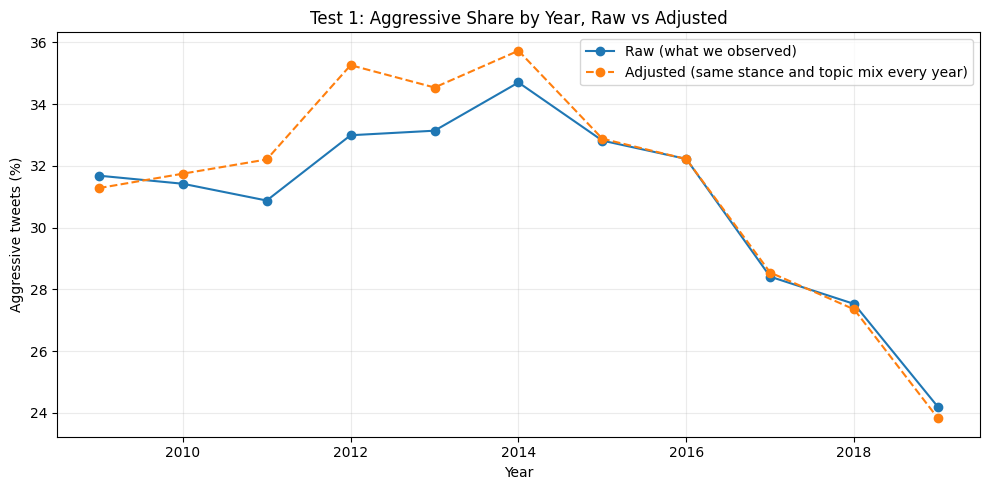

In [9]:
years = sorted(df["year"].unique())
raw_share = df.groupby("year")["aggressive"].mean() * 100
adj_share = pd.Series({y: adjusted_share(m1b, df, year=y) for y in years})

plt.figure(figsize=(10, 5))
plt.plot(raw_share.index, raw_share.values, marker="o", label="Raw (what we observed)")
plt.plot(adj_share.index, adj_share.values, marker="o", linestyle="--", label="Adjusted (same stance and topic mix every year)")
plt.xlabel("Year")
plt.ylabel("Aggressive tweets (%)")
plt.title("Test 1: Aggressive Share by Year, Raw vs Adjusted")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
save_fig("test1_aggression_by_year")
plt.show()

del m1a, m1b   # free memory: each fitted model keeps a copy of the data

### Interpretation

**How to read this:** if the adjusted OR for 2019 stays clearly below 1 and close to the raw OR, tweets really calmed down within each stance and topic. If it moves close to 1, the drop came mostly from the changing mix. In the chart, a gap between the two lines is the part explained by the mix.

*To fill in after running:*
- Raw OR, 2019 vs 2015: …
- Adjusted OR, 2019 vs 2015 (95% CI): …
- Answer in plain English: …

## 8. Test 1b — Does tone differ by topic?

Checkpoint 3 found mean sentiment ranging from about −0.20 (*Ideological Positions*) to +0.24 (*one-word hashtags*). Are these differences big, or just visible because we have so many tweets?

We use the **Kruskal–Wallis test**, which compares groups without assuming a bell-shaped distribution. That matters here because sentiment clusters at −0.5, 0 and +0.5. The test's p-value will be about 0 at this sample size, so the answer comes from the **effect size ε²** (epsilon squared): the share of the variation in sentiment that is explained by topic.

In [10]:
groups = [g["sentiment"].to_numpy() for _, g in df.groupby("topic")]
H, p_value = stats.kruskal(*groups)
epsilon_sq = H / (len(df) - 1)

print(f"Kruskal-Wallis H = {H:,.0f}, p = {p_value:.3g}")
print(f"Effect size epsilon squared = {epsilon_sq:.3f}")

# mean sentiment per topic with a 95% confidence interval
sent_by_topic = df.groupby("topic")["sentiment"].agg(["mean", "std", "count"])
sent_by_topic["ci_half_width"] = 1.96 * sent_by_topic["std"] / np.sqrt(sent_by_topic["count"])
sent_by_topic = sent_by_topic.sort_values("mean")
display(sent_by_topic)

Kruskal-Wallis H = 249,248, p = 0
Effect size epsilon squared = 0.063


,mean,std,count,ci_half_width
topic,,,,
Ideological Positions on Global Warming,-0.199,0.381,150481,0.002
Donald Trump versus Science,-0.160,0.438,248323,0.002
Impact of Resource Overconsumption,-0.102,0.413,123463,0.002
Politics,-0.085,0.405,452288,0.001
Weather Extremes,-0.082,0.444,612762,0.001
Seriousness of Gas Emissions,-0.046,0.408,224810,0.002
Significance of Pollution Awareness Events,-0.030,0.439,119915,0.002
Global stance,0.069,0.430,1030879,0.001
Importance of Human Intervention,0.070,0.436,648462,0.001


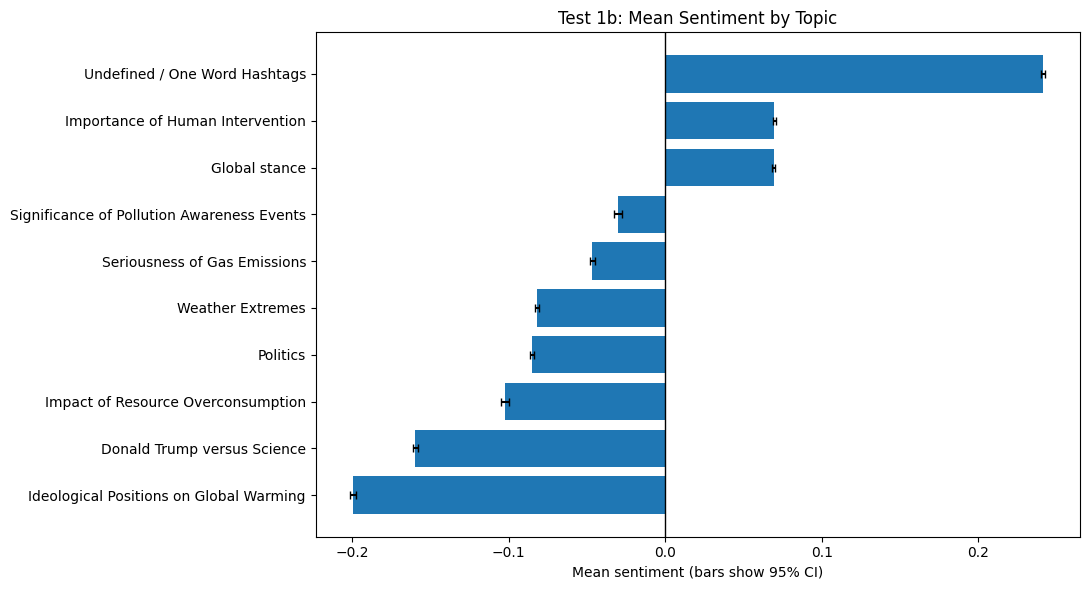

In [11]:
plt.figure(figsize=(11, 6))
plt.barh(sent_by_topic.index, sent_by_topic["mean"], xerr=sent_by_topic["ci_half_width"], capsize=3)
plt.axvline(0, linewidth=1, color="black")
plt.xlabel("Mean sentiment (bars show 95% CI)")
plt.title("Test 1b: Mean Sentiment by Topic")
plt.tight_layout()
save_fig("test1b_sentiment_by_topic")
plt.show()

### Interpretation

**How to read this:** a common rule of thumb for ε² is 0.01 = small, 0.06 = medium, 0.14 = large. The error bars will be very narrow because each topic has thousands of tweets, so any visible gap between topics is real. ε² says whether those gaps matter much compared with the spread of sentiment inside each topic.

*To fill in after running:*
- Epsilon squared: …
- Most negative and most positive topics: …
- Answer in plain English: …

## 9. Test 2 — Are deniers more aggressive within the same topic?

In Checkpoint 3, 42.6% of denier tweets were aggressive compared with 27.3% of believer tweets. But deniers also tweet more about aggressive topics such as politics. So we compare deniers and believers **within the same topic, year and gender label**:

- **Main model:** `aggressive ~ stance + topic + year + gender`
- **Add-on:** `aggressive ~ stance × political + year + gender` asks whether the denier–believer gap is different in political topics than in other topics (a question from our proposal).

In [12]:
m2 = fit_logit("aggressive ~ C(stance) + C(topic) + C(year) + C(gender)", df)
t2_table = odds_ratios(m2, keep="stance")
display(t2_table)
del m2   # free memory

,odds_ratio,ci_low,ci_high,p_value
stance = denier,1.820,1.805,1.835,0.000
stance = neutral,1.018,1.012,1.024,0.000


,denier vs believer OR
non-political topics,2.014
political topics,1.233


,odds_ratio,ci_low,ci_high,p_value
stance = denier:political,0.612,0.602,0.623,0.000
stance = neutral:political,0.801,0.790,0.813,0.000


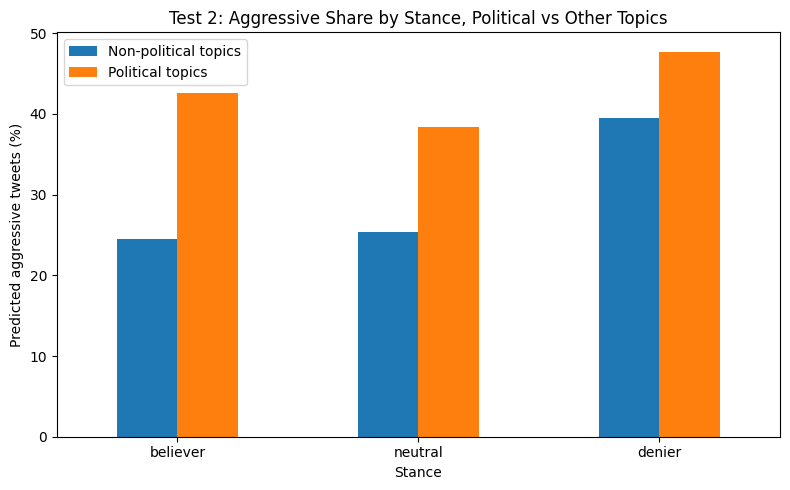

In [13]:
m2b = fit_logit("aggressive ~ C(stance) * political + C(year) + C(gender)", df)

# denier-vs-believer odds ratio inside non-political and inside political topics
b = m2b.params
t2_gap = pd.Series({
    "non-political topics": np.exp(b["C(stance)[T.denier]"]),
    "political topics": np.exp(b["C(stance)[T.denier]"] + b["C(stance)[T.denier]:political"]),
}, name="denier vs believer OR")
display(t2_gap.to_frame())
display(odds_ratios(m2b).filter(like=":political", axis=0))   # the interaction terms and their CIs

stances = ["believer", "neutral", "denier"]
t2_plot = pd.DataFrame({
    "Non-political topics": [adjusted_share(m2b, df, stance=s, political=0) for s in stances],
    "Political topics": [adjusted_share(m2b, df, stance=s, political=1) for s in stances],
}, index=stances)

t2_plot.plot(kind="bar", figsize=(8, 5), rot=0)
plt.ylabel("Predicted aggressive tweets (%)")
plt.xlabel("Stance")
plt.title("Test 2: Aggressive Share by Stance, Political vs Other Topics")
plt.tight_layout()
save_fig("test2_aggression_by_stance")
plt.show()

del m2b   # free memory

### Interpretation

**How to read this:** a denier OR above 1 (with the whole CI above 1) means deniers are more aggressive even when they tweet about the same topic as believers. For the add-on, an interaction OR below 1 means the denier–believer gap is smaller in political topics. Checkpoint 3 hinted at this: 52% vs 43% in Politics, but 60% vs 23% in one-word hashtag tweets.

*To fill in after running:*
- Denier vs believer OR (95% CI): …
- Gap in political vs non-political topics: …
- Answer in plain English: …

## 10. Test 3 — Is the gender gap in denial the same everywhere?

In Checkpoint 3, male-labelled tweets were more often denier in all six regions, but the gap ranged from 0.3 points (Asia) to 3.4 points (Oceania). Here we compute an odds ratio for **male vs female-labelled tweets being denier** in each region, with a 95% CI.

- Only tweets with a location and a male or female label are used.
- Inside each region we control for `year` as a simple trend, because some regions have very few tweets in some years.
- A second model with gender and region together checks whether **region matters more than gender** (a question from our proposal).

In [14]:
geo = df[df["region"].notna() & (df["region"] != "Other")].copy()   # tweets with one of the six regions
regions = geo["region"].value_counts().index.tolist()               # largest region first
g3 = geo[geo["gender"].isin(["male", "female"])]

rows = []
for region in regions:
    sub = g3[g3["region"] == region]
    m = fit_logit("denier ~ C(gender) + year", sub)
    r = odds_ratios(m, keep="gender").iloc[0]
    rows.append({"region": region, "tweets": len(sub), "denier_%": sub["denier"].mean() * 100,
                 "male_vs_female_OR": r["odds_ratio"], "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
t3_table = pd.DataFrame(rows).set_index("region")
display(t3_table)

# gender and region in one model (Asia, the region with the least denial, is the comparison)
m3_all = fit_logit("denier ~ C(gender) + C(region, Treatment('Asia')) + C(year)", g3)
display(odds_ratios(m3_all).filter(regex="^(gender|region)", axis=0))   # year rows left out
del m, m3_all   # free memory

,tweets,denier_%,male_vs_female_OR,ci_low,ci_high
region,,,,,
North America,839062,8.116,1.529,1.501,1.557
Europe,252366,4.603,1.963,1.874,2.056
Oceania,75158,7.064,1.891,1.756,2.037
Asia,62135,2.860,1.369,1.221,1.534
Africa & Middle East,33681,2.850,1.172,1.008,1.364
Latin America,19385,4.132,1.701,1.430,2.023


,odds_ratio,ci_low,ci_high,p_value
gender = male,1.587,1.562,1.613,0.000
region = Africa & Middle East,1.117,1.031,1.210,0.007
region = Europe,1.875,1.781,1.973,0.000
region = Latin America,1.642,1.507,1.788,0.000
region = North America,3.418,3.258,3.587,0.000
region = Oceania,2.920,2.763,3.086,0.000


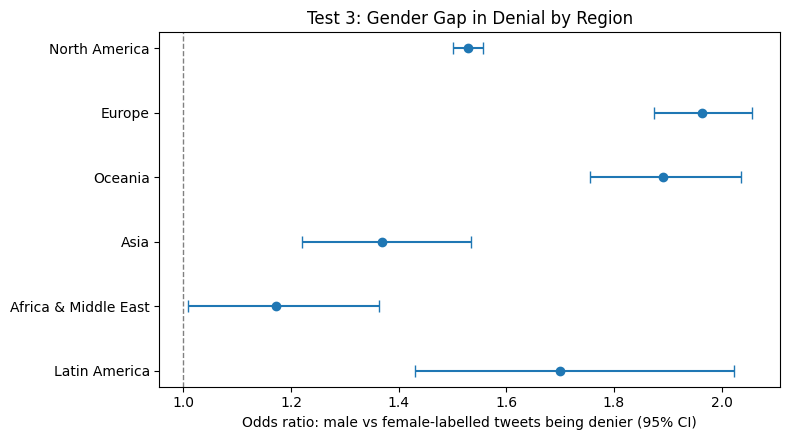

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y_pos = np.arange(len(t3_table))
ax.errorbar(
    t3_table["male_vs_female_OR"], y_pos,
    xerr=[t3_table["male_vs_female_OR"] - t3_table["ci_low"], t3_table["ci_high"] - t3_table["male_vs_female_OR"]],
    fmt="o", capsize=4,
)
ax.axvline(1, color="grey", linestyle="--", linewidth=1)   # OR = 1 means no gender gap
ax.set_yticks(y_pos)
ax.set_yticklabels(t3_table.index)
ax.invert_yaxis()
ax.set_xlabel("Odds ratio: male vs female-labelled tweets being denier (95% CI)")
ax.set_title("Test 3: Gender Gap in Denial by Region")
plt.tight_layout()
save_fig("test3_gender_gap_by_region")
plt.show()

### Interpretation

**How to read this:** a dot to the right of the dashed line (OR above 1) means male-labelled tweets are more likely to be denier in that region. If every CI sits right of the line, the gap is universal; dots far apart mean its size varies. In the second table, compare the gender OR with the region ORs: if the region ORs are bigger, where someone tweets from matters more than their gender label. Latin America and Africa & Middle East have few tweets, so expect wide CIs there.

*To fill in after running:*
- Regions where the gap is clear (CI above 1): …
- Largest and smallest gap: …
- Gender OR vs region ORs: …
- Answer in plain English: …

## 11. Test 3b — Do the same topics attract denial and aggression everywhere?

Checkpoint 3 compared each region's ranking of the 10 topics with the world ranking using a Spearman correlation (0.85–1.00 for denial, 0.65–0.99 for aggression) but did not test it. Here we add the p-value. Topics with too few tweets in a region are left out, using the same rule as CP3 (500 tweets in the full data, scaled to the sample: 125 at 25%).

With only 10 topics per region, the p-value is meaningful here, unlike in the tests on millions of tweets.

In [16]:
def topic_ranking_test(outcome):
    # Spearman correlation between each region's topic ranking and the world ranking.
    world = df.groupby("topic")[outcome].mean()
    rows = []
    for region in regions:
        by_topic = geo[geo["region"] == region].groupby("topic")[outcome].agg(["mean", "size"])
        by_topic = by_topic[by_topic["size"] >= 500 * SAMPLE_FRACTION]   # CP3 rule, scaled to the sample
        rho, p = stats.spearmanr(by_topic["mean"], world[by_topic.index])
        rows.append({"region": region, "topics": len(by_topic), "spearman_rho": rho, "p_value": p})
    return pd.DataFrame(rows).set_index("region")


t3b_denial = topic_ranking_test("denier")
t3b_aggr = topic_ranking_test("aggressive")
display(pd.concat({"denier share": t3b_denial, "aggressive share": t3b_aggr}, axis=1))

denier share                      aggressive share  \
                           topics spearman_rho p_value           topics   
region                                                                    
North America                  10        1.000   0.000               10   
Europe                         10        0.964   0.000               10   
Oceania                        10        0.939   0.000               10   
Asia                           10        0.842   0.002               10   
Africa & Middle East           10        0.976   0.000               10   
Latin America                  10        0.976   0.000               10   

                                           
                     spearman_rho p_value  
region                                     
North America               0.988   0.000  
Europe                      0.903   0.000  
Oceania                     0.794   0.006  
Asia                        0.636   0.048  
Africa & Middle East        0.915   0.000  
Latin America               0.915   0.000

### Interpretation

**How to read this:** rho close to 1 means the region ranks topics almost exactly like the world does. p < 0.05 means the match is unlikely to be chance.

*To fill in after running:*
- Range of rho for denial / aggression: …
- Any region where p ≥ 0.05: …
- Answer in plain English: …

## 12. Test 4 — Does the cold-month effect survive controls?

In Checkpoint 3, months at least 3 °C colder than normal had 1.7 times the share of *Weather Extremes* tweets and more denier tweets. But cold months were concentrated in 2009, 2010 and 2013, so year, region and temperature were tangled together. We untangle them here (tweets with a location only; the comparison bin is 0 to +1 °C):

- **Model A:** `weather_extremes ~ temp_bin` gives the raw effect.
- **Model B:** `weather_extremes ~ temp_bin + year + region + stance` gives the effect after controls.
- **Model C:** adds `temp_bin × stance` to check whether believers, neutrals and deniers react differently.

Everyone in the same region and month shares similar weather, so their tweets are not independent. Models B and C therefore use **cluster-robust errors** grouped by region and month. This makes the CIs honestly wider.

In [17]:
t4 = geo.dropna(subset=["temp_bin"]).copy()
clusters = pd.factorize(t4["region"] + "_" + t4["year"].astype(str) + "_" + t4["month"].astype(str))[0]

BIN = "C(temp_bin, Treatment('0 to 1'))"
m4a = fit_logit(f"weather_extremes ~ {BIN}", t4)
m4b = fit_logit(f"weather_extremes ~ {BIN} + C(year) + C(region) + C(stance)", t4, clusters=clusters)

raw4 = odds_ratios(m4a)
adj4 = odds_ratios(m4b, keep="temp_bin")
t4_table = pd.DataFrame({
    "tweets": t4["temp_bin"].value_counts(),
    "raw_OR": raw4["odds_ratio"].rename(lambda s: s.replace("temp_bin = ", "")),
    "adjusted_OR": adj4["odds_ratio"].rename(lambda s: s.replace("temp_bin = ", "")),
    "adjusted_ci_low": adj4["ci_low"].rename(lambda s: s.replace("temp_bin = ", "")),
    "adjusted_ci_high": adj4["ci_high"].rename(lambda s: s.replace("temp_bin = ", "")),
}).reindex(["<= -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"])
display(t4_table)   # "0 to 1" is the comparison bin, so it has no OR
del m4a, m4b   # free memory

,tweets,raw_OR,adjusted_OR,adjusted_ci_low,adjusted_ci_high
<= -3,148142,1.967,1.785,1.507,2.115
-3 to -1,196011,1.042,1.145,1.071,1.223
-1 to 0,119013,1.120,1.033,0.980,1.088
0 to 1,172554,NaN,NaN,NaN,NaN
1 to 3,264458,0.972,1.026,0.990,1.063
> 3,421980,1.079,1.317,1.158,1.498


,believer,neutral,denier
<= -3,14.300,30.700,31.700
-3 to -1,10.300,21.800,22.200
-1 to 0,9.400,19.900,22.300
0 to 1,9.100,19.800,20.300
1 to 3,9.300,20.600,19.700
> 3,12.100,23.300,21.600


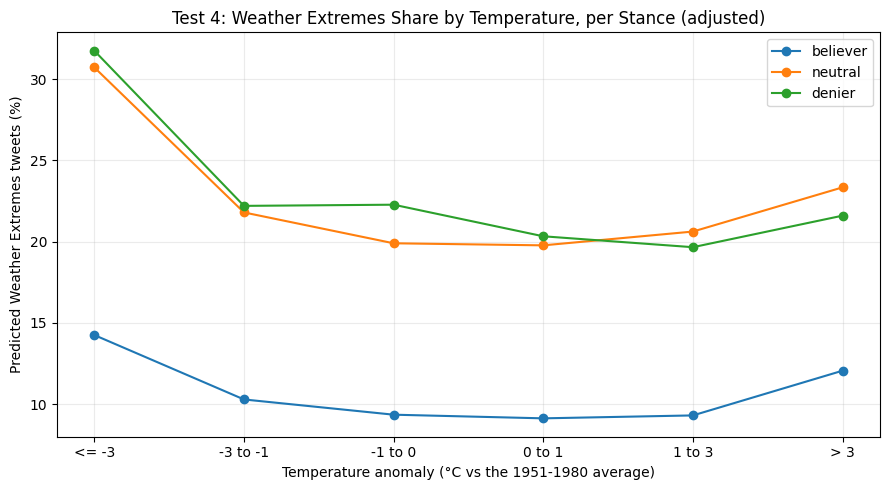

In [18]:
m4c = fit_logit(f"weather_extremes ~ {BIN} * C(stance) + C(year) + C(region)", t4, clusters=clusters)

bins = ["<= -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"]
t4_plot = pd.DataFrame({
    s: [adjusted_share(m4c, t4, temp_bin=b, stance=s) for b in bins] for s in ["believer", "neutral", "denier"]
}, index=bins)
display(t4_plot.round(1))

t4_plot.plot(marker="o", figsize=(9, 5))
plt.xlabel("Temperature anomaly (°C vs the 1951-1980 average)")
plt.ylabel("Predicted Weather Extremes tweets (%)")
plt.title("Test 4: Weather Extremes Share by Temperature, per Stance (adjusted)")
plt.grid(alpha=0.25)
plt.tight_layout()
save_fig("test4_weather_extremes_by_temperature")
plt.show()

del m4c   # free memory

In [19]:
# Second outcome: are cold months still linked to more denier tweets after controls?
m4d = fit_logit(f"denier ~ {BIN} + C(year) + C(region)", t4, clusters=clusters)
display(odds_ratios(m4d, keep="temp_bin"))
del m4d   # free memory

,odds_ratio,ci_low,ci_high,p_value
temp_bin = -1 to 0,1.013,0.968,1.061,0.574
temp_bin = -3 to -1,1.035,0.982,1.092,0.200
temp_bin = 1 to 3,0.966,0.931,1.003,0.069
temp_bin = <= -3,1.318,1.154,1.505,0.000
temp_bin = > 3,1.032,0.969,1.098,0.332


### Interpretation

**How to read this:** if the coldest bin's (<= -3) adjusted OR is still clearly above 1, the cold effect is not just an early-years or regional effect. In the chart, a steeper rise on the left for neutral and denier tweets than for believer tweets means they react more to cold months (CP3 saw about +15 points vs +6). The last table does the same for denial.

*To fill in after running:*
- Coldest bin, raw vs adjusted OR (95% CI): …
- Which stances react most: …
- Cold months and denial: …
- Answer in plain English: …

## 13. Predicting a tweet's stance (machine learning)

**Question:** can a tweet's stance (believer / neutral / denier) be predicted from its other labels?

- **Features, version 1 (all tweets):** topic, sentiment, aggressiveness, gender label, year.
- **Features, version 2 (tweets with a location):** the same, plus region and temperature anomaly.
- **Split:** 80% of tweets to train, 20% to test, keeping the same stance mix in both.

**Models:**
1. **Baseline:** always guesses "believer". Any real model has to beat it.
2. **Logistic regression:** a simple linear model.
3. **Random forest:** many decision trees that vote, which can pick up combinations of features.

Both real models use `class_weight="balanced"`, so the rare denier class (7.5% of tweets) is not ignored.

**Scores:**
- **Accuracy** is misleading here: 71.5% of tweets are believers, so the baseline already gets about 71%.
- **Macro-F1** is our main score. It averages the F1 score of the three classes, so each stance counts equally.
- **Denier recall** is the share of real denier tweets the model finds.

In [20]:
def run_stance_models(data, categorical, numeric, label):
    # Train the baseline, logistic regression and random forest, then score them on the test set.
    X = data[categorical + numeric]
    y = data["stance"].astype(str)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

    models = {
        "Baseline (always believer)": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "Random forest": RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50,
                                                class_weight="balanced", n_jobs=-1, random_state=SEED),
    }

    scores, fitted = [], {}
    for name, clf in models.items():
        # one-hot encode the categories, scale the numbers, then fit the classifier
        prep = ColumnTransformer([
            ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numbers", StandardScaler(), numeric),
        ])
        pipe = make_pipeline(prep, clf).fit(X_train, y_train)
        pred = pipe.predict(X_test)
        scores.append({
            "features": label,
            "model": name,
            "accuracy": accuracy_score(y_test, pred),
            "macro_F1": f1_score(y_test, pred, average="macro", zero_division=0),
            "denier_recall": recall_score(y_test, pred, labels=["denier"], average="macro", zero_division=0),
        })
        fitted[name] = pipe
    return pd.DataFrame(scores), fitted, X_test, y_test


scores_v1, fitted_v1, X_test_v1, y_test_v1 = run_stance_models(
    df, categorical=["topic", "aggressiveness", "gender", "year"], numeric=["sentiment"], label="version 1"
)
display(scores_v1)

,features,model,accuracy,macro_F1,denier_recall
0,version 1,Baseline (always believer),0.716,0.278,0.000
1,version 1,Logistic regression,0.564,0.450,0.569
2,version 1,Random forest,0.615,0.499,0.626


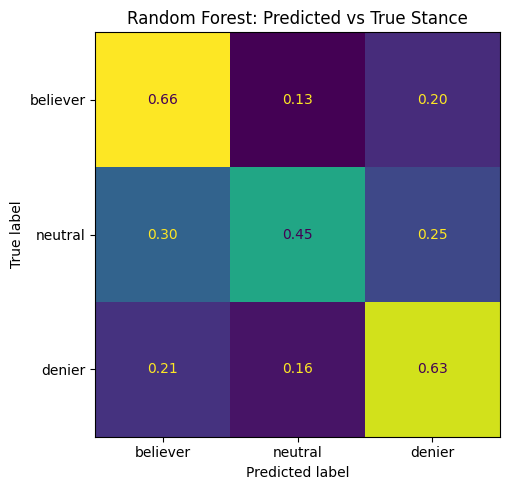

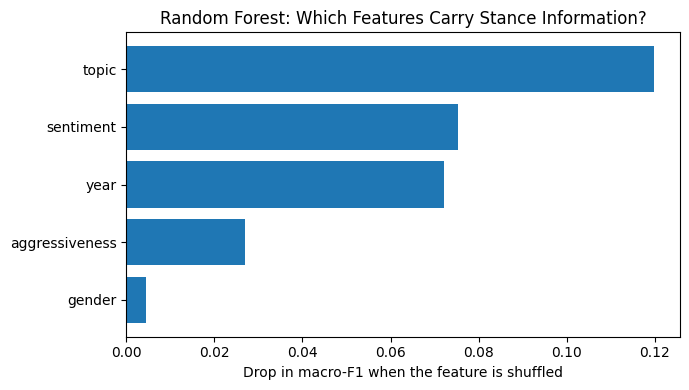

In [21]:
forest = fitted_v1["Random forest"]

# Confusion matrix: each row is a true stance, each column what the model predicted (rows add up to 1)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_v1, forest.predict(X_test_v1), labels=["believer", "neutral", "denier"],
    normalize="true", values_format=".2f", colorbar=False, ax=ax,
)
ax.set_title("Random Forest: Predicted vs True Stance")
plt.tight_layout()
save_fig("model_confusion_matrix")
plt.show()

# Permutation importance: how much macro-F1 drops when one feature is shuffled (on 20,000 test tweets)
small = X_test_v1.sample(min(len(X_test_v1), 20_000), random_state=SEED)
imp = permutation_importance(forest, small, y_test_v1.loc[small.index], scoring="f1_macro",
                             n_repeats=5, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=small.columns).sort_values()

plt.figure(figsize=(7, 4))
plt.barh(importance.index, importance.values)
plt.xlabel("Drop in macro-F1 when the feature is shuffled")
plt.title("Random Forest: Which Features Carry Stance Information?")
plt.tight_layout()
save_fig("model_feature_importance")
plt.show()

del fitted_v1, forest, X_test_v1, y_test_v1   # free memory before version 2

In [22]:
# Version 2: tweets with a location, adding region and temperature anomaly
scores_v2, _, _, _ = run_stance_models(
    geo, categorical=["topic", "aggressiveness", "gender", "year", "region"],
    numeric=["sentiment", "temperature_avg"], label="version 2 (with location)",
)
model_scores = pd.concat([scores_v1, scores_v2], ignore_index=True)
display(model_scores)

,features,model,accuracy,macro_F1,denier_recall
0,version 1,Baseline (always believer),0.716,0.278,0.000
1,version 1,Logistic regression,0.564,0.450,0.569
2,version 1,Random forest,0.615,0.499,0.626
3,version 2 (with location),Baseline (always believer),0.745,0.285,0.000
4,version 2 (with location),Logistic regression,0.571,0.439,0.590
5,version 2 (with location),Random forest,0.599,0.468,0.637


### Interpretation

**How to read this:** beating the baseline on macro-F1 means the other labels carry real information about stance. A low denier recall means stance can't be read reliably from these labels alone; the tweet text would be needed, which the dataset does not include. If version 2 scores barely higher than version 1, location and temperature add little. All features and the stance itself are ML-made labels, so the model shows how the labels relate, not people's real views.

*To fill in after running:*
- Macro-F1: baseline / logistic regression / random forest: …
- Denier recall: …
- Most important features: …
- Does location help (version 2)? …
- Answer in plain English: …

## 14. Results summary

One row per test with its key number. This table goes into the blog post's *What we found* section and the summary slide. It is also saved as `results_summary.csv`.

In [23]:
t1_2019 = t1_table.loc["year = 2019"]
t2_denier = t2_table.loc["stance = denier"]
t4_cold = t4_table.loc["<= -3"]
forest_v1 = scores_v1.set_index("model").loc["Random forest"]
logit_v1 = scores_v1.set_index("model").loc["Logistic regression"]
base_v1 = scores_v1.set_index("model").loc["Baseline (always believer)"]

summary = pd.DataFrame([
    {"test": "Test 1", "question": "Did tweets calm down, or did the stance/topic mix change?",
     "method": "Logistic regression, raw vs adjusted for stance and topic",
     "key_result": f"2019 vs 2015 OR: raw {t1_2019['raw_OR']:.2f}, adjusted {t1_2019['adjusted_OR']:.2f} "
                   f"(95% CI {t1_2019['adjusted_ci_low']:.2f}-{t1_2019['adjusted_ci_high']:.2f})"},
    {"test": "Test 1b", "question": "Does sentiment differ by topic?",
     "method": "Kruskal-Wallis test + effect size",
     "key_result": f"H = {H:,.0f}, epsilon squared = {epsilon_sq:.3f}"},
    {"test": "Test 2", "question": "Are deniers more aggressive within the same topic?",
     "method": "Logistic regression with topic, year, gender",
     "key_result": f"denier vs believer OR = {t2_denier['odds_ratio']:.2f} "
                   f"(95% CI {t2_denier['ci_low']:.2f}-{t2_denier['ci_high']:.2f}); "
                   f"political {t2_gap['political topics']:.2f}, non-political {t2_gap['non-political topics']:.2f}"},
    {"test": "Test 3", "question": "Is the gender gap in denial the same in every region?",
     "method": "Logistic regression per region",
     "key_result": f"male vs female OR from {t3_table['male_vs_female_OR'].min():.2f} "
                   f"({t3_table['male_vs_female_OR'].idxmin()}) to {t3_table['male_vs_female_OR'].max():.2f} "
                   f"({t3_table['male_vs_female_OR'].idxmax()})"},
    {"test": "Test 3b", "question": "Do the same topics attract denial and aggression everywhere?",
     "method": "Spearman rank correlation with p-values",
     "key_result": f"rho {t3b_denial['spearman_rho'].min():.2f}-{t3b_denial['spearman_rho'].max():.2f} (denial), "
                   f"{t3b_aggr['spearman_rho'].min():.2f}-{t3b_aggr['spearman_rho'].max():.2f} (aggression)"},
    {"test": "Test 4", "question": "Does the cold-month effect survive controls for year and region?",
     "method": "Logistic regression with cluster-robust errors",
     "key_result": f"coldest bin OR: raw {t4_cold['raw_OR']:.2f}, adjusted {t4_cold['adjusted_OR']:.2f} "
                   f"(95% CI {t4_cold['adjusted_ci_low']:.2f}-{t4_cold['adjusted_ci_high']:.2f})"},
    {"test": "Model", "question": "Can stance be predicted from a tweet's other labels?",
     "method": "Baseline vs logistic regression vs random forest",
     "key_result": f"macro-F1: baseline {base_v1['macro_F1']:.2f}, logistic {logit_v1['macro_F1']:.2f}, "
                   f"forest {forest_v1['macro_F1']:.2f}; denier recall {forest_v1['denier_recall']:.2f}"},
])

summary.to_csv("results_summary.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(summary)

,test,question,method,key_result
0,Test 1,"Did tweets calm down, or did the stance/topic mix change?","Logistic regression, raw vs adjusted for stance and topic","2019 vs 2015 OR: raw 0.65, adjusted 0.63 (95% CI 0.62-0.64)"
1,Test 1b,Does sentiment differ by topic?,Kruskal-Wallis test + effect size,"H = 249,248, epsilon squared = 0.063"
2,Test 2,Are deniers more aggressive within the same topic?,"Logistic regression with topic, year, gender","denier vs believer OR = 1.82 (95% CI 1.80-1.83); political 1.23, non-political 2.01"
3,Test 3,Is the gender gap in denial the same in every region?,Logistic regression per region,male vs female OR from 1.17 (Africa & Middle East) to 1.96 (Europe)
4,Test 3b,Do the same topics attract denial and aggression everywhere?,Spearman rank correlation with p-values,"rho 0.84-1.00 (denial), 0.64-0.99 (aggression)"
5,Test 4,Does the cold-month effect survive controls for year and region?,Logistic regression with cluster-robust errors,"coldest bin OR: raw 1.97, adjusted 1.79 (95% CI 1.51-2.12)"
6,Model,Can stance be predicted from a tweet's other labels?,Baseline vs logistic regression vs random forest,"macro-F1: baseline 0.28, logistic 0.45, forest 0.50; denier recall 0.63"


### Key findings

*To fill in after running: one line per test answering its question (Yes / No / Partly, and why).*

1. Test 1 — …
2. Test 1b — …
3. Test 2 — …
4. Test 3 — …
5. Test 3b — …
6. Test 4 — …
7. Model — …

## 15. Limitations

- **Twitter users are not representative of the general population**, so these results are not public-opinion estimates.
- **Every label is a model's guess.** Stance, topic, sentiment, aggressiveness and gender were all predicted by ML models from the tweet text and profile, and we cannot check them one by one. Some links between labels may come from the labelling models reacting to the same words.
- **Associations, not causes.** Even after controls, these tests show which patterns hold up, not why they happen.
- **Location covers only about a third of tweets**, and about 65% of those are North American, so Tests 3, 3b and 4 describe that third.
- **Temperature is a monthly, regional anomaly**, not the weather on the day of the tweet.
- **We used a 25% random sample** so the models fit in memory. Section 5 shows it matches the full data.
- **The stance classifier only sees other labels, not the tweet text**, so a modest score says more about the dataset than about how predictable stance is.

## 16. Save the outputs (Colab)

The charts are in `figures/` and the key numbers in `results_summary.csv`. On Colab these files disappear when the session ends, so zip and download them (and use *File → Download → Download .ipynb* to keep the notebook with its outputs).

In [25]:
# Colab only: uncomment to zip the charts and results and download them
!zip -r cp4_outputs.zip figures results_summary.csv
from google.colab import files
files.download("cp4_outputs.zip")

  adding: figures/ (stored 0%)
  adding: figures/test1_aggression_by_year.png (deflated 10%)
  adding: figures/model_feature_importance.png (deflated 22%)
  adding: figures/test4_weather_extremes_by_temperature.png (deflated 10%)
  adding: figures/test3_gender_gap_by_region.png (deflated 20%)
  adding: figures/test2_aggression_by_stance.png (deflated 20%)
  adding: figures/test1b_sentiment_by_topic.png (deflated 24%)
  adding: figures/model_confusion_matrix.png (deflated 16%)
  adding: results_summary.csv (deflated 45%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>